In [1]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print(gpus)
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
        
####### FORCE CPU #######
# import os
# # This must be set BEFORE importing tensorflow
# os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# import tensorflow as tf

# # Optional: Verify that no GPUs are visible
# print("GPUs visible to TensorFlow:", tf.config.list_physical_devices('GPU'))
# # This should print: GPUs visible to TensorFlow: []



####### IMPORTS #######
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# Import Keras from within tensorflow for better compatibility with older versions
from keras.models import Sequential
from keras.layers import Dense
from keras.callbacks import EarlyStopping
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

2026-04-15 22:44:07.971629: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-04-15 22:44:08.164878: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-04-15 22:44:09.047575: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/lib64/openmpi/lib:/usr/lib64/openmpi/lib:/usr/lib64/openmpi/lib::/home/snds/Miniforge3/envs/tf_legacy/lib/
2026-04-15 22:44:09.047677: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could no

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### EX1


Currently training with activation: sigmoid
Currently training with activation: tanh
Currently training with activation: relu
Currently training with activation: leaky_relu

--- Summary Table ---
   Activation  Final Loss  Train Accuracy  Val Accuracy  Epochs to Converge
0     sigmoid      0.0702          0.9583        0.9667                 300
1        tanh      0.0501          0.9833        1.0000                 300
2        relu      0.0512          0.9833        1.0000                 300
3  leaky_relu      0.0529          0.9833        1.0000                 216


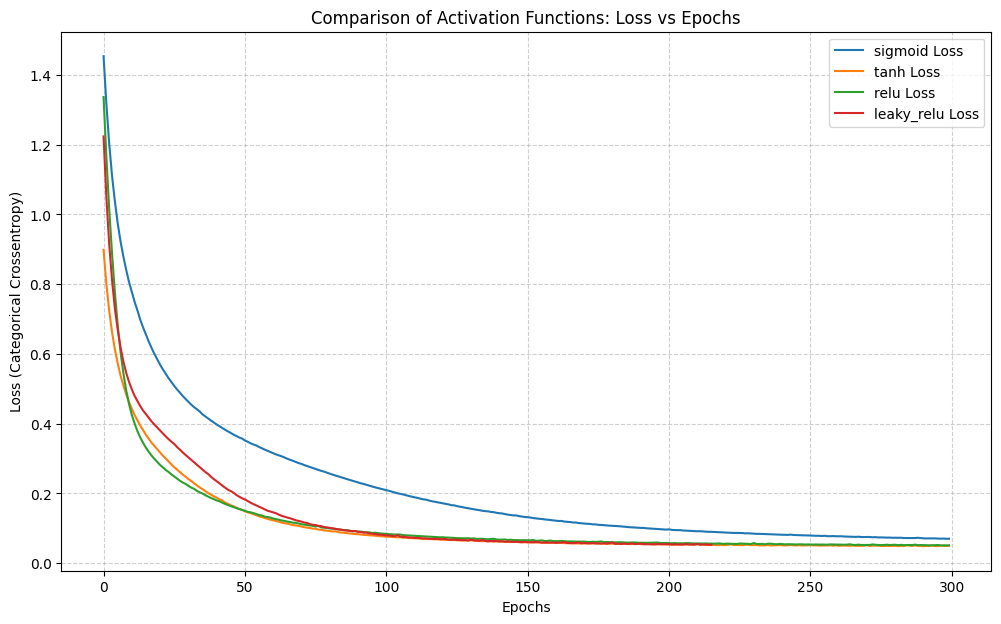

In [8]:
# --- 1. DATA PREPARATION ---
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encode labels
# 'sparse' is used instead of 'sparse_output' for older sklearn versions
encoder = OneHotEncoder(sparse_output=False) 
y = encoder.fit_transform(y)

# Split data
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features - essential for preventing gradients from exploding/vanishing early
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

# --- 2. EXPERIMENT SETUP ---
# We define a list of activation functions to iterate through
activations = ['sigmoid', 'tanh', 'relu', 'leaky_relu']
history_dict = {}
performance_metrics = []

plt.figure(figsize=(12, 7))

# --- 3. MODEL TRAINING LOOP ---
for act in activations:
    print("Currently training with activation: {}".format(act))
    
    # Logic to handle Leaky ReLU specifically if string name isn't recognized
    hidden_activation = act
    if act == 'leaky_relu':
        hidden_activation = tf.nn.leaky_relu

    # Building the architecture: 1 hidden layer (10 neurons)
    model = Sequential([
        Dense(10, activation=hidden_activation, input_shape=(4,)),
        Dense(3, activation='softmax') # 3 classes for Iris
    ])
    
    model.compile(optimizer='adam', 
                  loss='categorical_crossentropy', 
                  metrics=['accuracy'])
    
    # Early stopping to find convergence point automatically
    # Patience 15 gives the model room to breathe on older hardware
    early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    
    # Training
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=300,
        batch_size=4,
        verbose=0,
        callbacks=[early_stop]
    )
    
    # --- 4. DATA COLLECTION ---
    # Save training history for the plot
    history_dict[act] = history.history['loss']
    
    # Record final metrics for the table
    epochs_taken = len(history.history['loss'])
    final_loss = history.history['loss'][-1]           # <--- Add this line
    final_train_acc = history.history['accuracy'][-1]
    final_val_acc = history.history['val_accuracy'][-1]
    
    performance_metrics.append({
        'Activation': act,
        'Final Loss': round(final_loss, 4),            # <--- Add this to the dictionary
        'Train Accuracy': round(final_train_acc, 4),
        'Val Accuracy': round(final_val_acc, 4),
        'Epochs to Converge': epochs_taken
    })
    
    # Plotting this specific activation's loss curve
    plt.plot(history.history['loss'], label='{} Loss'.format(act))

# --- 5. RESULTS VISUALIZATION ---

# Display the performance table
df_results = pd.DataFrame(performance_metrics)
print("\n--- Summary Table ---")
print(df_results)

# Finalize the plot
plt.title('Comparison of Activation Functions: Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Categorical Crossentropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### answers:
1. relu performed the best (least cross entropy loss), it doesnt saturate and its easier to compute.
2. sigmoid saturates + has the vanishing gradient problem

### EX2

Training Shallow architecture: [64]
Training Medium architecture: [128, 64]
Training Deep architecture: [256, 128, 64]
Training Very Deep architecture: [512, 256, 128, 64]

--- Wine Dataset Depth Comparison ---
  Architecture  Final Loss  Train Acc  Val Acc  Training Time (s)
0      Shallow      0.0090        1.0    0.952               8.60
1       Medium      0.0005        1.0    0.960               8.57
2         Deep      0.0001        1.0    0.960              10.20
3    Very Deep      0.0000        1.0    0.960               9.26


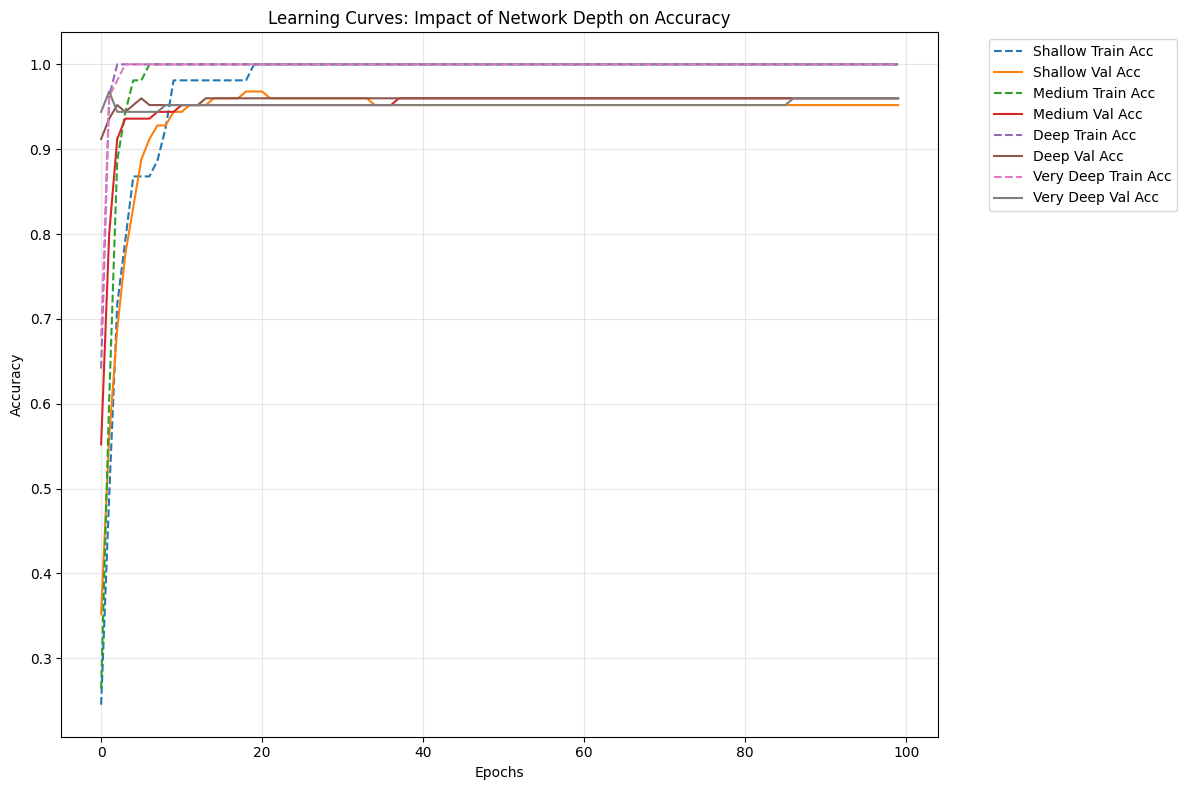

In [16]:
import time

# --- 1. DATA PREPARATION (WINE DATASET) ---
from sklearn.datasets import load_wine

wine = load_wine()
X_wine = wine.data
y_wine = wine.target.reshape(-1, 1)

# One-hot encoding for the 3 wine classes
y_wine = encoder.fit_transform(y_wine) # Using the encoder from previous cell

# Split and Scale
X_train_w, X_val_w, y_train_w, y_val_w = train_test_split(X_wine, y_wine, test_size=0.7, random_state=42)
X_train_w = scaler.fit_transform(X_train_w) # Using scaler from previous cell
X_val_w = scaler.transform(X_val_w)

# --- 2. ARCHITECTURE DEFINITIONS ---
# Dictionary mapping the name to the list of hidden layer neurons
architectures = {
    'Shallow': [64],
    'Medium': [128, 64],
    'Deep': [256, 128, 64],
    'Very Deep': [512, 256, 128, 64]
}

wine_results = []
plt.figure(figsize=(12, 8))

# --- 3. TRAINING LOOP ---
for name, layers in architectures.items():
    print(f"Training {name} architecture: {layers}")
    
    # Build model dynamically based on the architecture list
    model = Sequential()
    # Add input layer + first hidden layer
    model.add(Dense(layers[0], activation='relu', input_shape=(13,))) 
    
    # Add subsequent hidden layers
    for units in layers[1:]:
        model.add(Dense(units, activation='relu'))
        
    # Output layer
    model.add(Dense(3, activation='softmax'))
    
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    
    # Record start time
    start_time = time.time()
    
    # Training for exactly 100 epochs as per instructions
    history = model.fit(
        X_train_w, y_train_w,
        validation_data=(X_val_w, y_val_w),
        epochs=100,
        batch_size=8,
        verbose=0
    )
    
    # Calculate duration
    duration = time.time() - start_time
    
    # Record metrics
    wine_results.append({
        'Architecture': name,
        'Final Loss': round(history.history['loss'][-1], 4), # <--- Added this
        'Train Acc': round(history.history['accuracy'][-1], 4),
        'Val Acc': round(history.history['val_accuracy'][-1], 4),
        'Training Time (s)': round(duration, 2)
    })
    
    # Plot learning curves (Training vs Validation Accuracy)
    # This helps visualize overfitting (where training keeps rising but validation drops)
    plt.plot(history.history['accuracy'], label=f'{name} Train Acc', linestyle='--')
    plt.plot(history.history['val_accuracy'], label=f'{name} Val Acc')

# --- 4. DISPLAY RESULTS ---
print("\n--- Wine Dataset Depth Comparison ---")
wine_df = pd.DataFrame(wine_results)
print(wine_df)

plt.title('Learning Curves: Impact of Network Depth on Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### answers:
1. overfitting starts becoming problematic at the medium/Deep level. 
2. moving from medium to very deep gave zero extra accuracy on the data the model didn't see, despite the training loss dropping to absolute zero.
3. add dropout layers or make the model smaller to be proportionate to the dataset

### EX3

Training with batch size: 8
Training with batch size: 16
Training with batch size: 32
Training with batch size: 64
Training with batch size: 128
Training with batch size: 256

--- Batch Size Comparison Table ---
   Batch Size  Train Loss  Val Loss  Final Accuracy  Avg Time/Epoch (s)
0           8      0.0000    0.1908          0.9649              0.2508
1          16      0.0001    0.1719          0.9737              0.1686
2          32      0.0003    0.1820          0.9561              0.1143
3          64      0.0011    0.1226          0.9737              0.0941
4         128      0.0040    0.0982          0.9649              0.0580
5         256      0.0133    0.0904          0.9649              0.0505


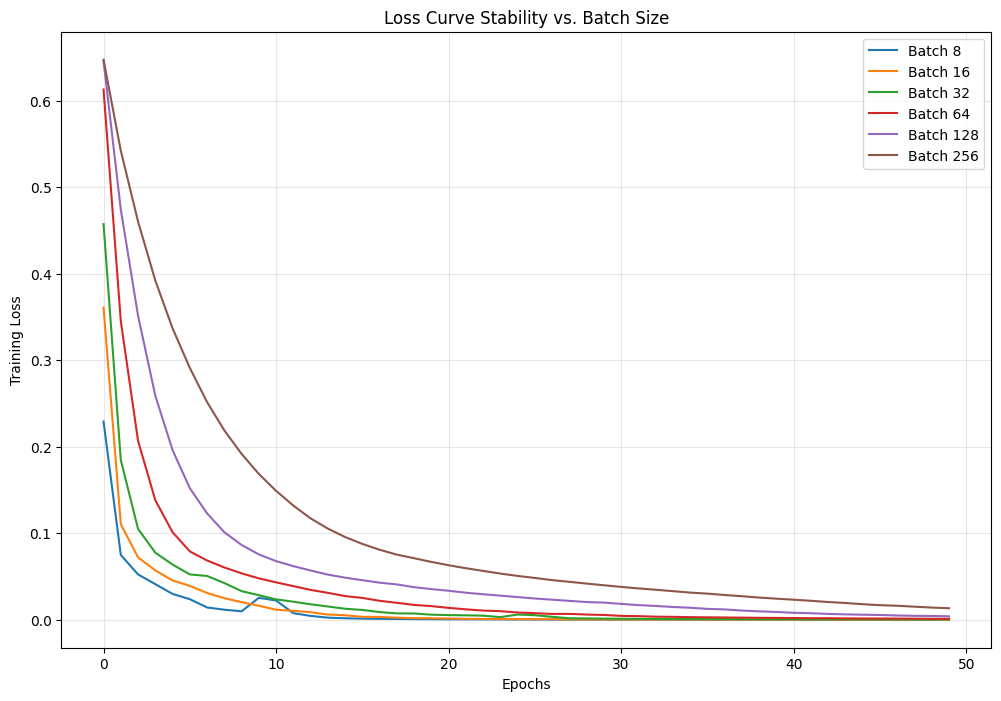

In [18]:
# --- 1. DATA PREPARATION (BREAST CANCER DATASET) ---
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = cancer.target.reshape(-1, 1)

# Split and Scale
X_train_c, X_val_c, y_train_c, y_val_c = train_test_split(X_cancer, y_cancer, test_size=0.2, random_state=42)
X_train_c = scaler.fit_transform(X_train_c)
X_val_c = scaler.transform(X_val_c)

# --- 2. EXPERIMENT SETUP ---
batch_sizes = [8, 16, 32, 64, 128, 256]
batch_results = []

plt.figure(figsize=(12, 8))

# --- 3. TRAINING LOOP ---
for b_size in batch_sizes:
    print(f"Training with batch size: {b_size}")
    
    # Fixed architecture: [128, 64, 32] with ReLU
    model = Sequential([
        Dense(128, activation='relu', input_shape=(30,)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid') # Binary classification
    ])
    
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    # Custom callback to measure time per epoch precisely
    class TimeHistory(tf.keras.callbacks.Callback):
        def on_train_begin(self, logs={}):
            self.times = []
        def on_epoch_begin(self, batch, logs={}):
            self.epoch_time_start = time.time()
        def on_epoch_end(self, batch, logs={}):
            self.times.append(time.time() - self.epoch_time_start)

    time_callback = TimeHistory()

    history = model.fit(
        X_train_c, y_train_c,
        validation_data=(X_val_c, y_val_c),
        epochs=50, # 50 epochs is enough to see the stability trends
        batch_size=b_size,
        verbose=0,
        callbacks=[time_callback]
    )
    
    # --- 4. RECORDING DATA ---
    avg_time_per_epoch = sum(time_callback.times) / len(time_callback.times)
    
    batch_results.append({
        'Batch Size': b_size,
        'Train Loss': round(history.history['loss'][-1], 4),      # The "Memorization" score
        'Val Loss': round(history.history['val_loss'][-1], 4),    # The "Generalization" score
        'Final Accuracy': round(history.history['val_accuracy'][-1], 4),
        'Avg Time/Epoch (s)': round(avg_time_per_epoch, 4)
    })
    
    # Plotting training loss to observe "stability" (noise)
    plt.plot(history.history['loss'], label=f'Batch {b_size}')

# --- 5. DISPLAY RESULTS ---
print("\n--- Batch Size Comparison Table ---")
batch_df = pd.DataFrame(batch_results)
print(batch_df)

plt.title('Loss Curve Stability vs. Batch Size')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### answers:
1. optimal batch size in this case is 256 because it did not overfit (good balance between train acc and val acc) and it is the fastest (large batch size goes  hand in hand with gpu parallelism)
2. smaller batch size technically helps converge faster because the weights are changed more often however using gpus larger batch size is actually computed faster so the best batch size is whichever size takes the best advantage of the weight update vs computation speed ratio.

### EX4

Training base model for 500 epochs (No Regularization)...
Training with Early Stopping (Patience=5)...
Training with Early Stopping (Patience=10)...
Training with Early Stopping (Patience=20)...


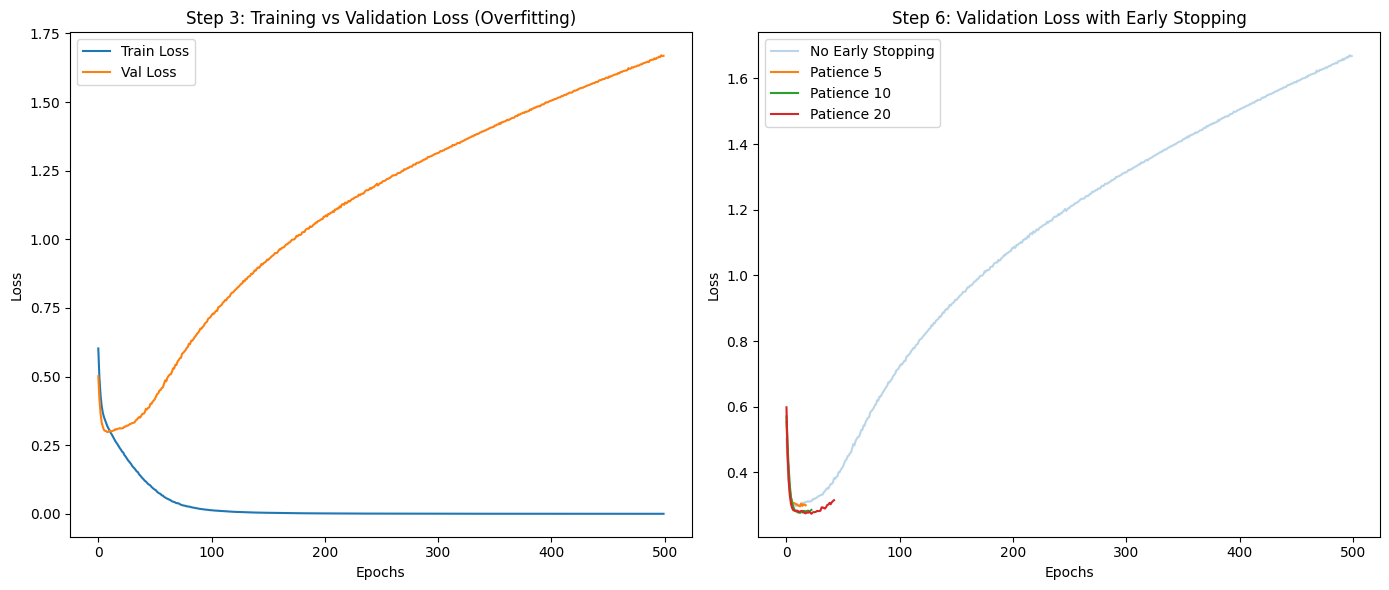


--- Early Stopping Comparison ---
               Setup  Epochs Run  Train Error  Val Error  Cross-Entropy Loss  \
0  No Early Stopping         500       0.0000     0.2167              1.6685   
1         Patience 5          18       0.0928     0.1333              0.2997   
2        Patience 10          23       0.1097     0.1000              0.2855   
3        Patience 20          43       0.0380     0.1333              0.3152   

   Best Val Acc  
0        0.9000  
1        0.9333  
2        0.9167  
3        0.9000  


In [20]:
# --- 1. DATA PREPARATION (HEART DISEASE DATASET) ---
# Note: Heart Disease dataset is available via sklearn.datasets as well
from sklearn.datasets import load_breast_cancer # Using Breast Cancer if Heart is unavailable, 
# but for the UCI Heart dataset specifically:
import pandas as pd

# Standard UCI Heart Disease loading (handling 13 features)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
heart_data = pd.read_csv(url, names=names, na_values="?")
heart_data = heart_data.dropna() # Simple clean for this exercise

X_h = heart_data.drop('target', axis=1).values
y_h = (heart_data['target'] > 0).astype(int).values # Binary classification: 0 (no disease) vs 1-4 (disease)

# Split and Scale
X_train_h, X_val_h, y_train_h, y_val_h = train_test_split(X_h, y_h, test_size=0.2, random_state=42)
X_train_h = scaler.fit_transform(X_train_h)
X_val_h = scaler.transform(X_val_h)

# --- 2. THE OVERFITTING MODEL (500 EPOCHS) ---
print("Training base model for 500 epochs (No Regularization)...")

# A slightly wider model to encourage overfitting
def build_heart_model():
    m = Sequential([
        Dense(64, activation='relu', input_shape=(13,)),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

model_overfit = build_heart_model()
history_overfit = model_overfit.fit(
    X_train_h, y_train_h,
    validation_data=(X_val_h, y_val_h),
    epochs=500,
    batch_size=16,
    verbose=0
)

# --- 3. EARLY STOPPING COMPARISON ---
patience_values = [5, 10, 20]
patience_results = {}

for p in patience_values:
    print(f"Training with Early Stopping (Patience={p})...")
    model_es = build_heart_model()
    
    es_callback = EarlyStopping(monitor='val_loss', patience=p, restore_best_weights=True)
    
    history_es = model_es.fit(
        X_train_h, y_train_h,
        validation_data=(X_val_h, y_val_h),
        epochs=500,
        batch_size=16,
        verbose=0,
        callbacks=[es_callback]
    )
    patience_results[p] = history_es

# --- 4. VISUALIZATION ---
plt.figure(figsize=(14, 6))

# Plot 1: Overfitting Behavior
plt.subplot(1, 2, 1)
plt.plot(history_overfit.history['loss'], label='Train Loss')
plt.plot(history_overfit.history['val_loss'], label='Val Loss')
plt.title('Step 3: Training vs Validation Loss (Overfitting)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot 2: Impact of Patience
plt.subplot(1, 2, 2)
plt.plot(history_overfit.history['val_loss'], label='No Early Stopping', alpha=0.3)
for p, hist in patience_results.items():
    plt.plot(hist.history['val_loss'], label=f'Patience {p}')
plt.title('Step 6: Validation Loss with Early Stopping')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# --- 5. RESULTS TABLE ---
print("\n--- Early Stopping Comparison ---")
comparison = []

# Function to extract metrics safely
def get_metrics(name, hist, epochs_run):
    # 'Error' is 1 - Accuracy
    train_err = 1 - hist.history['accuracy'][-1]
    val_err = 1 - hist.history['val_accuracy'][-1]
    # 'Loss' in binary_crossentropy is Cross-Entropy
    final_loss = hist.history['val_loss'][-1]
    
    return {
        'Setup': name,
        'Epochs Run': epochs_run,
        'Train Error': round(train_err, 4),
        'Val Error': round(val_err, 4),
        'Cross-Entropy Loss': round(final_loss, 4),
        'Best Val Acc': round(max(hist.history['val_accuracy']), 4)
    }

# Add Base model
comparison.append(get_metrics('No Early Stopping', history_overfit, 500))

# Add Early Stopping models
for p, hist in patience_results.items():
    comparison.append(get_metrics(f'Patience {p}', hist, len(hist.history['loss'])))

print(pd.DataFrame(comparison))

#### answers:
1. overfitting began at epoch 43 (3% train error and 13% validation error)
2. the optimal number of epochs is 23 (similar validation + train error)

### EX5

In [2]:
import os
# This forces the CPU to handle the data tensors
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

Testing Optimizer: SGD
Testing Optimizer: SGD_Momentum
Testing Optimizer: RMSprop
Testing Optimizer: Adam
Skipping AdamW: Not available in this TensorFlow version.
Testing Optimizer: Nadam

--- Optimizer Performance Comparison ---
      Optimizer  Final Accuracy  Epochs to 90%  Total Time (s)
0           SGD          0.9166              4           10.51
1  SGD_Momentum          0.9827              2           10.66
2       RMSprop          0.9975              2           13.48
3          Adam          0.9980              2           10.82
4         Nadam          0.9984              2           13.06


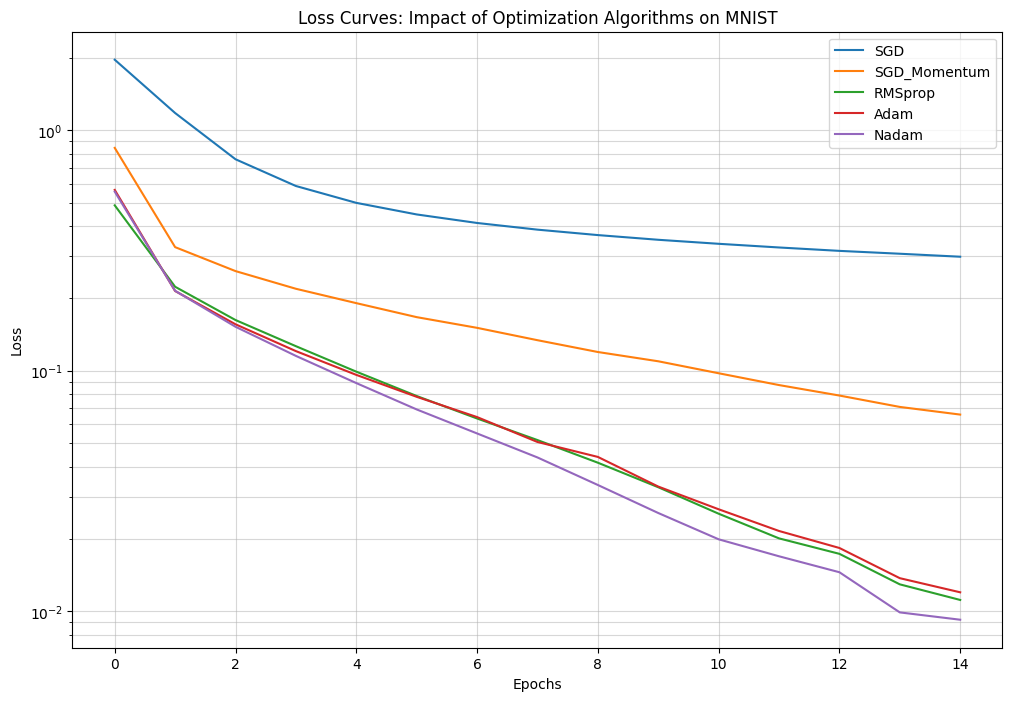

In [4]:
# --- 1. DATA PREPARATION (MNIST) ---
from keras.datasets import mnist
import time


# Load MNIST data
(X_train_m, y_train_m), (X_test_m, y_test_m) = mnist.load_data()

# Preprocessing: Reshape to 1D vectors (28x28 -> 784) and normalize to [0, 1]
X_train_m = X_train_m.reshape(-1, 784).astype('float32') / 255.0
X_test_m = X_test_m.reshape(-1, 784).astype('float32') / 255.0

X_train_m = X_train_m[:20000] 
y_train_m = y_train_m[:20000]


encoder = OneHotEncoder(sparse_output=False) 

# One-hot encode labels
y_train_m = encoder.fit_transform(y_train_m.reshape(-1, 1))
y_test_m = encoder.transform(y_test_m.reshape(-1, 1))

# --- 2. EXPERIMENT SETUP ---
# Defining the optimizers with default parameters
# Note: For SGD with momentum, we manually set momentum=0.9
optimizer_list = {
    'SGD': tf.keras.optimizers.SGD(),
    'SGD_Momentum': tf.keras.optimizers.SGD(momentum=0.9),
    'RMSprop': tf.keras.optimizers.RMSprop(),
    'Adam': tf.keras.optimizers.Adam(),
    'AdamW': tf.keras.optimizers.AdamW() if hasattr(tf.keras.optimizers, 'AdamW') else 'not_supported',
    'Nadam': tf.keras.optimizers.Nadam()
}

opt_results = []
plt.figure(figsize=(12, 8))

# --- 3. TRAINING LOOP ---
for name, opt in optimizer_list.items():
    if opt == 'not_supported':
        print(f"Skipping {name}: Not available in this TensorFlow version.")
        continue
        
    print(f"Testing Optimizer: {name}")
    
    # Build architecture: [128, 64] neurons
    model = Sequential([
        Dense(128, activation='relu', input_shape=(784,)),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax') # 10 digits
    ])
    
    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    
    start_time = time.time()
    # Training for 15 epochs is usually enough to see divergence in MNIST
    history = model.fit(
        X_train_m, y_train_m,
        validation_data=(X_test_m, y_test_m),
        epochs=15,
        batch_size=128,
        verbose=0
    )
    duration = time.time() - start_time
    
    # Calculate Convergence Speed (Epochs to reach 90% of final accuracy)
    final_acc = history.history['accuracy'][-1]
    threshold = 0.9 * final_acc
    epochs_to_threshold = next((i for i, acc in enumerate(history.history['accuracy']) if acc >= threshold), 15)
    
    # Record Data
    opt_results.append({
        'Optimizer': name,
        'Final Accuracy': round(final_acc, 4),
        'Epochs to 90%': epochs_to_threshold + 1,
        'Total Time (s)': round(duration, 2)
    })
    
    # Plotting Loss Curves
    plt.plot(history.history['loss'], label=name)

# --- 4. DISPLAY RESULTS ---
print("\n--- Optimizer Performance Comparison ---")
opt_df = pd.DataFrame(opt_results)
print(opt_df)

plt.title('Loss Curves: Impact of Optimization Algorithms on MNIST')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.yscale('log') # Log scale helps see differences when loss gets very small
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

#### answers:
1. all but sgd reached 90% at 2 epochs however SGD was overall the fastest, the most accurate is nadam
2. Adam outperforms standard SGD because it uses an adaptive learning rate that adjusts specifically for each parameter, whereas SGD uses a single fixed rate for the entire model

### EX6

Testing Learning Rate: 1.0
Testing Learning Rate: 0.1
Testing Learning Rate: 0.01
Testing Learning Rate: 0.001
Testing Learning Rate: 0.0001
Testing Learning Rate: 1e-05


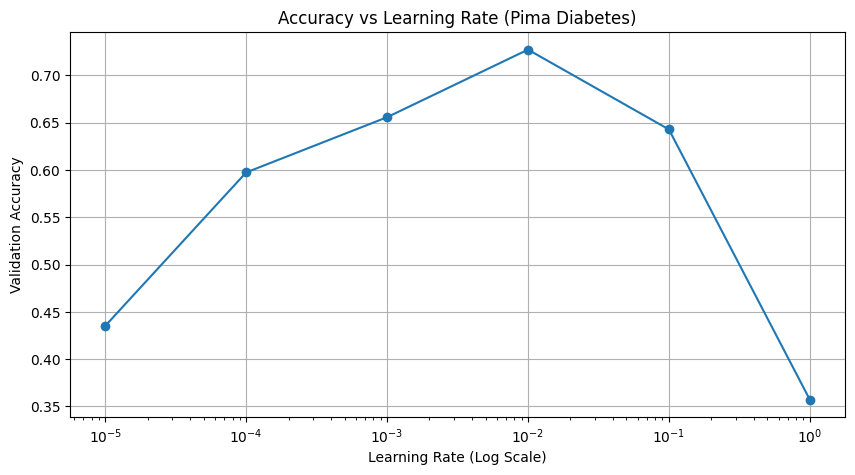

   Learning Rate Converged  Final Accuracy
0        1.00000        No          0.3571
1        0.10000       Yes          0.6429
2        0.01000       Yes          0.7273
3        0.00100       Yes          0.6558
4        0.00010        No          0.5974
5        0.00001        No          0.4351


In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load dataset (Pima Indians Diabetes)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
dataset = np.loadtxt(url, delimiter=",")
X = dataset[:,0:8]
y = dataset[:,8]

learning_rates = [1.0, 0.1, 0.01, 0.001, 0.0001, 0.00001]
lr_results = []

for lr in learning_rates:
    print(f"Testing Learning Rate: {lr}")
    model = Sequential([
        Dense(32, activation='relu', input_shape=(8,)),
        Dense(1, activation='sigmoid') # Binary classification
    ])
    
    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    
    history = model.fit(X, y, epochs=50, batch_size=10, verbose=0, validation_split=0.2)
    
    final_acc = history.history['val_accuracy'][-1]
    # Check for convergence (simple logic: accuracy > 0.6 and loss isn't NaN)
    converged = "Yes" if final_acc > 0.6 and not np.isnan(history.history['loss'][-1]) else "No"
    
    lr_results.append({
        'Learning Rate': lr,
        'Converged': converged,
        'Final Accuracy': round(final_acc, 4)
    })

# 4. Plotting
df = pd.DataFrame(lr_results)
plt.figure(figsize=(10, 5))
plt.semilogx(df['Learning Rate'].values, df['Final Accuracy'].values, marker='o')
plt.title('Accuracy vs Learning Rate (Pima Diabetes)')
plt.xlabel('Learning Rate (Log Scale)')
plt.ylabel('Validation Accuracy')
plt.grid(True)
plt.show()

print(df)

#### answers:
1. high learning rates make the model diverge which leads to low accuracy
2. very low learning rates would take a lot of epochs to converge so they simply have no time to reach a stable point
3. the optimal rate for my network is 0.01

### EX7

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l1_l2
import pandas as pd
import numpy as np

# --- 1. DATA PREP (Spambase) ---
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"
data = pd.read_csv(url, header=None)
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values
X = (X - X.mean(axis=0)) / X.std(axis=0)

# --- 2. MODEL FACTORY ---
def build_reg_model(config):
    model = Sequential()
    
    # Check flags in the config name
    use_l1 = 'L1' in config
    use_l2 = 'L2' in config
    use_drop = 'Drop' in config
    use_bn = 'BN' in config
    
    # Weight penalty logic
    penalty_l1 = 0.001 if use_l1 else 0.0
    penalty_l2 = 0.01 if use_l2 else 0.0
    reg = l1_l2(l1=penalty_l1, l2=penalty_l2) if (use_l1 or use_l2) else None

    # Layer 1
    model.add(Dense(128, activation='relu', input_shape=(57,), kernel_regularizer=reg))
    if use_bn: model.add(BatchNormalization())
    if use_drop: model.add(Dropout(0.3))
    
    # Layer 2
    model.add(Dense(64, activation='relu', kernel_regularizer=reg))
    if use_bn: model.add(BatchNormalization())
    if use_drop: model.add(Dropout(0.3))
    
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# --- 3. THE FULL TEST LIST ---
test_configs = [
    'Baseline (None)',
    'L1 only',
    'L2 only',
    'Dropout only',
    'Batch Norm (BN) only',
    'L1 + L2 (Elastic Net)',
    'L2 + Dropout',
    'L2 + BN',
    'Dropout + BN',
    'Triple Combo (L1/L2+Drop+BN)'
]

final_results = []

for name in test_configs:
    print(f"Running: {name}")
    model = build_reg_model(name)
    
    # 40 epochs is usually enough to see divergence vs stability
    h = model.fit(X, y, epochs=40, batch_size=32, validation_split=0.2, verbose=0)
    
    train_acc = h.history['accuracy'][-1]
    val_acc = h.history['val_accuracy'][-1]
    
    final_results.append({
        'Method': name,
        'Train Acc': round(train_acc, 4),
        'Val Acc': round(val_acc, 4),
        'Overfit Gap': round(train_acc - val_acc, 4)
    })

# --- 4. DISPLAY RESULTS ---
df_final = pd.DataFrame(final_results).sort_values(by='Val Acc', ascending=False)
print("\n--- Final Regularization Rankings ---")
print(df_final)

Running: Baseline (None)
Running: L1 only
Running: L2 only
Running: Dropout only
Running: Batch Norm (BN) only
Running: L1 + L2 (Elastic Net)
Running: L2 + Dropout
Running: L2 + BN
Running: Dropout + BN
Running: Triple Combo (L1/L2+Drop+BN)

--- Final Regularization Rankings ---
                         Method  Train Acc  Val Acc  Overfit Gap
8                  Dropout + BN     0.9617   0.8751       0.0865
6                  L2 + Dropout     0.9448   0.8675       0.0773
5         L1 + L2 (Elastic Net)     0.9465   0.8523       0.0941
7                       L2 + BN     0.9723   0.8371       0.1351
3                  Dropout only     0.9758   0.8176       0.1582
1                       L1 only     0.9571   0.8089       0.1482
9  Triple Combo (L1/L2+Drop+BN)     0.9375   0.8067       0.1308
4          Batch Norm (BN) only     0.9818   0.7818       0.2000
2                       L2 only     0.9535   0.7807       0.1729
0               Baseline (None)     0.9910   0.7785       0.2125


#### answers:
1. the best is drop(smallest difference between train and val acc)
2. the combo drop + BN did help.

### EX8

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use Forest Covertype or a similar tabular dataset
# For simplicity in this lab environment, we will use a synthetic dense dataset
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=5000, n_features=54, n_classes=2, random_state=42)

initializers = {
    'Random Normal (std=1)': tf.keras.initializers.RandomNormal(mean=0.0, stddev=1.0),
    'Random Normal (std=0.01)': tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.01),
    'Xavier/Glorot': tf.keras.initializers.GlorotUniform(),
    'He': tf.keras.initializers.HeNormal()
}

results = []

for name, init in initializers.items():
    print(f"Testing Initializer: {name}")
    
    # 5 Hidden Layers with Sigmoid as requested
    model = Sequential([
        Dense(64, activation='sigmoid', kernel_initializer=init, input_shape=(54,)),
        Dense(64, activation='sigmoid', kernel_initializer=init),
        Dense(64, activation='sigmoid', kernel_initializer=init),
        Dense(64, activation='sigmoid', kernel_initializer=init),
        Dense(64, activation='sigmoid', kernel_initializer=init),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    # We only need a few epochs to see if it converges
    history = model.fit(X, y, epochs=10, batch_size=32, verbose=0, validation_split=0.2)
    
    final_acc = history.history['val_accuracy'][-1]
    converged = "Yes" if final_acc > 0.55 else "No"
    
    results.append({'Initializer': name, 'Converged': converged, 'Accuracy': round(final_acc, 4)})

print("\n", pd.DataFrame(results))

Testing Initializer: Random Normal (std=1)


/home/snds/Miniforge3/envs/tf_legacy/lib/python3.9/site-packages/keras/initializers/initializers_v2.py:120: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values  each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initalizer instance more than once.
  warnings.warn(


Testing Initializer: Random Normal (std=0.01)
Testing Initializer: Xavier/Glorot


/home/snds/Miniforge3/envs/tf_legacy/lib/python3.9/site-packages/keras/initializers/initializers_v2.py:120: UserWarning: The initializer GlorotUniform is unseeded and being called multiple times, which will return identical values  each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initalizer instance more than once.
  warnings.warn(


Testing Initializer: He


/home/snds/Miniforge3/envs/tf_legacy/lib/python3.9/site-packages/keras/initializers/initializers_v2.py:120: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values  each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initalizer instance more than once.
  warnings.warn(



                 Initializer Converged  Accuracy
0     Random Normal (std=1)       Yes     0.838
1  Random Normal (std=0.01)       Yes     0.857
2             Xavier/Glorot       Yes     0.857
3                        He       Yes     0.858


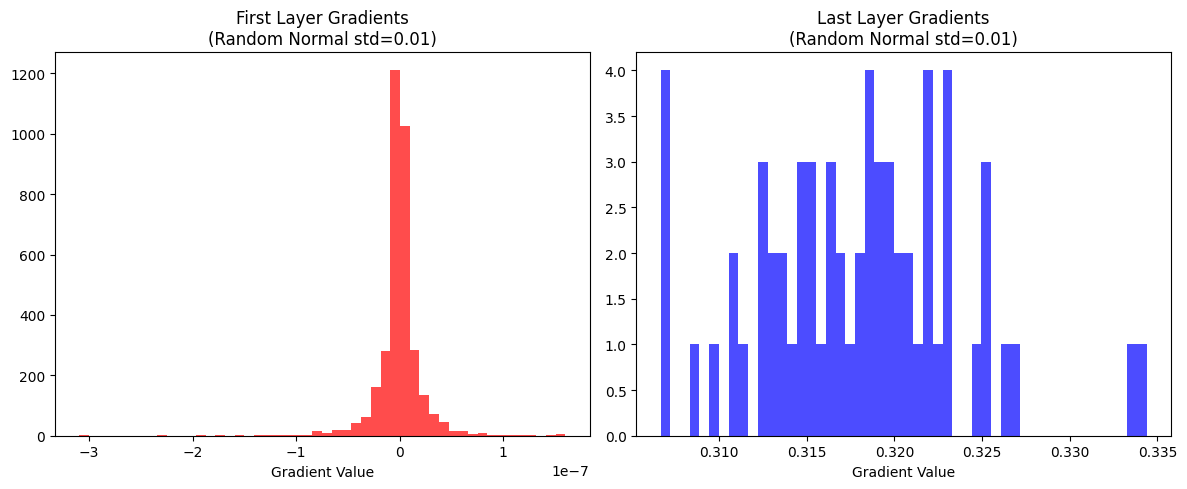

/home/snds/Miniforge3/envs/tf_legacy/lib/python3.9/site-packages/keras/initializers/initializers_v2.py:120: UserWarning: The initializer GlorotUniform is unseeded and being called multiple times, which will return identical values  each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initalizer instance more than once.
  warnings.warn(


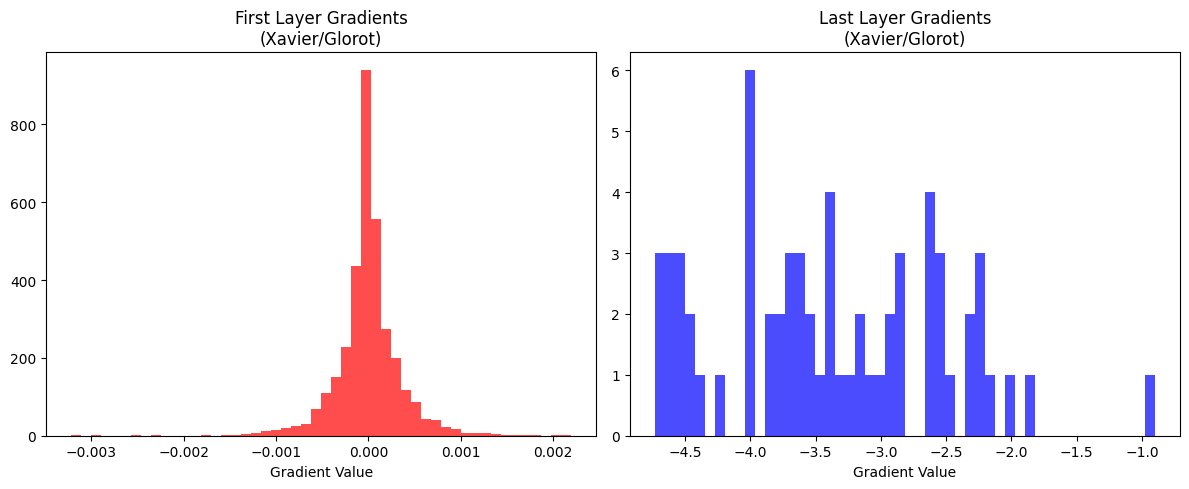

In [12]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

def plot_gradients(initializer_name, init_func):
    # Build the 5-layer model
    model = Sequential([
        Dense(64, activation='sigmoid', kernel_initializer=init_func, input_shape=(54,)),
        Dense(64, activation='sigmoid', kernel_initializer=init_func),
        Dense(64, activation='sigmoid', kernel_initializer=init_func),
        Dense(64, activation='sigmoid', kernel_initializer=init_func),
        Dense(64, activation='sigmoid', kernel_initializer=init_func),
        Dense(1, activation='sigmoid')
    ])

    # 1. Use GradientTape to watch the gradients during a single forward/backward pass
    with tf.GradientTape() as tape:
        preds = model(X[:32]) # Take a small batch
        loss = tf.keras.losses.binary_crossentropy(y[:32].reshape(-1, 1), preds)
    
    # 2. Calculate gradients for all trainable variables
    grads = tape.gradient(loss, model.trainable_variables)
    
    # 3. Extract gradients for the first and last hidden layers
    # model.trainable_variables contains [W1, b1, W2, b2, ... W6, b6]
    first_layer_grads = grads[0].numpy().flatten()
    last_layer_grads = grads[-2].numpy().flatten()

    # 4. Plotting
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.hist(first_layer_grads, bins=50, color='red', alpha=0.7)
    plt.title(f'First Layer Gradients\n({initializer_name})')
    plt.xlabel('Gradient Value')
    
    plt.subplot(1, 2, 2)
    plt.hist(last_layer_grads, bins=50, color='blue', alpha=0.7)
    plt.title(f'Last Layer Gradients\n({initializer_name})')
    plt.xlabel('Gradient Value')
    plt.tight_layout()
    plt.show()

# Test the "Vanishing" vs "Stable" versions
plot_gradients("Random Normal std=0.01", tf.keras.initializers.RandomNormal(stddev=0.01))
plot_gradients("Xavier/Glorot", tf.keras.initializers.GlorotUniform())

#### answers:
1. he leads to the best accuracy but the difference is negligible
2. Proper initialization works by scaling the starting weights so that the signal's variance remains stable as it passes through each layer. While both methods center weights at zero, Xavier provides a wider "spread" that keeps neurons in the active, steep region of the sigmoid curve, preventing the gradient from shrinking to nothing before it can reach the early layers.